# Decoupled training comparison: Phase 2 (imbalance) + Phase 3 (toxicity)

Notebook 03 showed the Phase 1 baseline's headline numbers (81.2% top-1,
95.6% top-5) hide a severe split by how much training data a species
had - under-20-image species scored far worse than well-represented
ones. This notebook plans and then compares the Phase 2/3 follow-up:
**decoupled training** (Kang et al., *Decoupling Representation and
Classifier for Long-Tailed Recognition*, ICLR 2020, arXiv:1910.09217) -
freeze the Phase 1 backbone, cache its features once, and train only a
fresh classifier head per variant. See `CLAUDE.md`'s "Phase 2/3
approach" section for the full reasoning (why decoupling rather than
continued fine-tuning, and why this project's I/O-bound hardware makes
it disproportionately attractive here).

Three points of comparison, same metric suite each time:
**Phase 1 baseline** -> **+ Phase 2** (imbalance-aware head) ->
**+ Phase 2 + Phase 3** (also toxicity-aware). This is a
proof-of-concept, not a final system - the goal is seeing whether each
step moves the numbers at all, not picking a production model yet.

## Proposed runs

**1. Feature extraction** (remote GPU, one-time per split) - reuses the
finished `plantnet-baseline` checkpoint (30 epochs, val top-1 81.2%,
val top-5 95.6%) with `model.fc` swapped for `nn.Identity()`. One
forward pass per split, no augmentation, no backward pass:

- `extract-features --run plantnet-baseline --split train`
  (243,866 images - still I/O-bound reading from the HDD, so expect
  this close to one training epoch's wall-clock, roughly 70-90 min)
- `extract-features --run plantnet-baseline --split val`
  (31,115 images, a few minutes)
- `extract-features --run plantnet-baseline --split test`
  (31,106 images, a few minutes)

**2. Sanity check** (`decoupled.sanity_check_extraction`), right after
val features exist: run them back through the backbone's **original,
untouched** `fc` layer and confirm top-1/top-5 match 81.2%/95.6%
exactly. If they don't, something in extraction is wrong (transform,
layer, normalization) - fix before trusting anything downstream.

**3. Baseline eval from cached features**
(`decoupled.baseline_eval_from_features`, val and test) - gives Phase 1
a row in the *same* metric suite the Phase 2/3 variants get (top-1/3/
5/10, avg-k, `toxic_confusion_rate`), instead of reusing the old
two-number `metrics.json` from training time (predates
`toxic_confusion_rate` entirely).

**4. Six classifier-head training runs** (remote, cheap - minutes
each, all reusing the same cached train features):

| config | loss | toxicity cost | purpose |
|---|---|---|---|
| `decoupled_ce` | plain CE | off | control - isolates "does decoupling alone help" from "does the new loss help" |
| `decoupled_cb_loss` | Class-Balanced (Cui et al. 2019) | off | Phase 2 |
| `decoupled_balanced_softmax` | Balanced Softmax (Ren et al. 2020) | off | Phase 2, alternative |
| `decoupled_cb_toxicity` | Class-Balanced | on (weight 1.0) | Phase 2 + 3 combined |
| `decoupled_balanced_softmax_toxicity` | Balanced Softmax | on (weight 1.0) | Phase 2 + 3 combined, alternative |

**Tunable parameters** (each loss has exactly one dedicated knob,
besides the generic `lr`/`epochs`/`batch_size`/`toxicity_cost_weight`
every config already exposes):
- `cb_beta` (CB-loss only, default `0.9999`) - how aggressively rare
  classes get upweighted via the effective-number-of-samples formula;
  closer to 1 is more aggressive.
- `balanced_softmax_tau` (Balanced Softmax only, default `1.0`) - a
  generalized scaling on the `log(n_c/N)` logit adjustment (the
  "logit adjustment" framing, Menon et al. 2021): `tau=0` disables it
  (reduces to plain CE), `tau>1` pushes harder toward balance.

**5. Hyperparameter sweeps** (also cheap - same reasoning as above:
head-only training on already-cached features has no image I/O, so
each additional config costs minutes, not another hour of feature
extraction). One parameter varied at a time, holding everything else
at its config's default, 3 values each:

| sweep | parameter | values | configs |
|---|---|---|---|
| CB-loss | `cb_beta` | 0.99 / 0.999 / 0.9999 | `decoupled_cb_loss_beta0.99`, `decoupled_cb_loss_beta0.999`, `decoupled_cb_loss` |
| Balanced Softmax | `balanced_softmax_tau` | 0.5 / 1.0 / 1.5 | `decoupled_balanced_softmax_tau0.5`, `decoupled_balanced_softmax`, `decoupled_balanced_softmax_tau1.5` |
| CB + toxicity | `toxicity_cost_weight` | 0.5 / 1.0 / 2.0 | `decoupled_cb_toxicity_w0.5`, `decoupled_cb_toxicity`, `decoupled_cb_toxicity_w2.0` |
| Balanced Softmax + toxicity | `toxicity_cost_weight` | 0.5 / 1.0 / 2.0 | `decoupled_balanced_softmax_toxicity_w0.5`, `decoupled_balanced_softmax_toxicity`, `decoupled_balanced_softmax_toxicity_w2.0` |

That's 13 configs total (5 from the main comparison + 8 new sweep
points - 4 of the "center" values are shared with the main comparison,
so only 8 new files were actually needed).

**6. Evaluate each head on val only** for this screening comparison
(`evaluate-classifier --split val`) - **test is reserved** for a final
check on whichever variant(s) look best, so we're not repeatedly
peeking at test while iterating.

**7. The comparison table/plots below** read whatever
`outputs/*/eval_val.json` (+ the baseline's
`eval_from_features_val.json`) files already exist. Nothing has been
run yet as of writing this notebook - every cell is written to show
"pending" rather than error until the real runs land.

**Open questions, flagging rather than deciding unilaterally:**
- `toxicity_cost_weight`'s sweep (0.5/1.0/2.0) is centered on a guess,
  not a principled midpoint - if the real sweet spot turns out to sit
  outside this range, worth extending it rather than assuming these
  3 points bracket it.
- The two toxicity-weight sweeps (CB-loss base vs. Balanced Softmax
  base) might show different optimal weights - worth comparing them
  side by side rather than assuming one generalizes to the other.
- 50 epochs/config for head-only training is a guess at "cheap enough
  to be generous" - easy to shorten if a config's printed per-epoch
  loss visibly plateaus early.

In [41]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from plant_toxicity_checker.config import REPO_ROOT

%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 90}}
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200)

BACKBONE_RUN = "plantnet-baseline"
SPLIT = "val"  # the screening split for this comparison - test is
               # reserved for a final check on the best variant(s) only

# label -> (run name, eval filename under outputs/<run>/)
RUNS = {
    "Phase 1 baseline": (
        BACKBONE_RUN, f"eval_from_features_{SPLIT}.json",
    ),
    "Phase 2: CE (control)": ("decoupled_ce", f"eval_{SPLIT}.json"),
    "Phase 2: CB-loss": ("decoupled_cb_loss", f"eval_{SPLIT}.json"),
    "Phase 2: Balanced Softmax": (
        "decoupled_balanced_softmax", f"eval_{SPLIT}.json",
    ),
    "Phase 2+3: CB-loss + toxicity cost": (
        "decoupled_cb_toxicity", f"eval_{SPLIT}.json",
    ),
    "Phase 2+3: Balanced Softmax + toxicity cost": (
        "decoupled_balanced_softmax_toxicity", f"eval_{SPLIT}.json",
    ),
}

## Run status

Which of the planned runs have actually produced results so far.

In [42]:
def load_eval(run_name, filename):
    path = REPO_ROOT / "outputs" / run_name / filename
    if not path.exists():
        return None
    return json.loads(path.read_text(encoding="utf-8"))


results = {label: load_eval(run, filename) for label, (run, filename) in RUNS.items()}

for label, result in results.items():
    status = "done" if result is not None else "pending - not yet run"
    print(f"{label:38s} {status}")

Phase 1 baseline                       done
Phase 2: CE (control)                  done
Phase 2: CB-loss                       done
Phase 2: Balanced Softmax              done
Phase 2+3: CB-loss + toxicity cost     done
Phase 2+3: Balanced Softmax + toxicity cost done


## Comparison table

`avg-5` is average-k accuracy at k=5 (calibrated on val, same
convention as notebook 03); `toxic confusion` is the fraction of
known-side species whose top-1 prediction crosses the toxic/non-toxic
boundary (lower is better) - the metric Phase 3 specifically targets.
Rows for runs that haven't happened yet show `NaN`, not an error.

In [43]:
def row_for(result):
    if result is None:
        return {
            "top-1": np.nan, "top-5": np.nan, "avg-5": np.nan,
            "toxic confusion": np.nan, "ambiguous": np.nan,
        }
    confusion = result["toxic_confusion"]
    return {
        "top-1": result["top_1"],
        "top-5": result["top_5"],
        "avg-5": result["avg_5"],
        "toxic confusion": confusion["confusion_rate"],
        "ambiguous": confusion["ambiguous_rate"],
    }


comparison = pd.DataFrame(
    {label: row_for(result) for label, result in results.items()}
).T
comparison.style.format(
    {
        "top-1": "{:.1%}", "top-5": "{:.1%}", "avg-5": "{:.1%}",
        # 2 decimals here - the toxicity-cost-term deltas this project
        # cares about are sub-0.2-percentage-point, lost at 1 decimal.
        "toxic confusion": "{:.2%}", "ambiguous": "{:.2%}",
    },
    na_rep="pending",
)

,top-1,top-5,avg-5,toxic confusion,ambiguous
Phase 1 baseline,81.2%,95.6%,97.2%,0.90%,4.46%
Phase 2: CE (control),80.5%,95.1%,96.6%,0.91%,4.42%
Phase 2: CB-loss,75.6%,94.2%,95.9%,0.96%,5.57%
Phase 2: Balanced Softmax,69.8%,89.3%,91.6%,1.19%,6.96%
Phase 2+3: CB-loss + toxicity cost,75.8%,94.1%,95.8%,0.85%,5.48%
Phase 2+3: Balanced Softmax + toxicity cost,69.9%,89.4%,91.7%,0.98%,7.26%


## Species-ID accuracy by variant

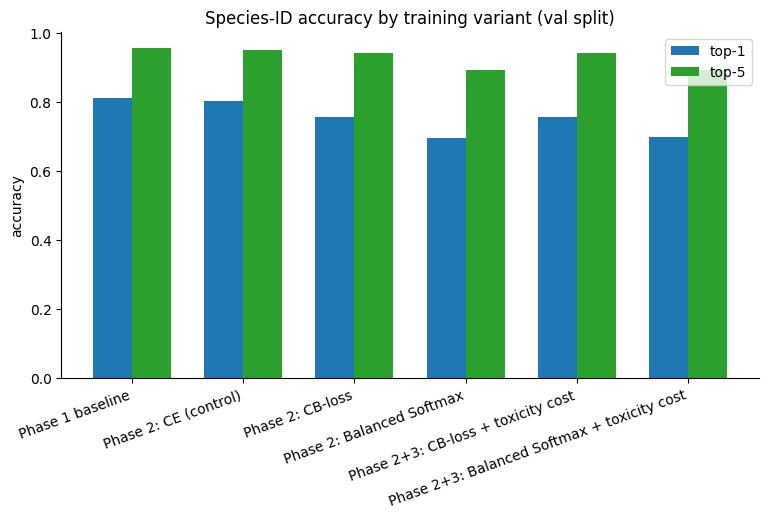

In [44]:
present = comparison.dropna(how="all")
if present.empty:
    print("No runs completed yet - nothing to plot. See 'Proposed runs' "
          "above for the plan; this cell renders once at least one "
          "outputs/<run>/eval_val.json (or the baseline's "
          "eval_from_features_val.json) exists.")
else:
    fig, ax = plt.subplots(figsize=(9, 4.5))
    x = np.arange(len(present))
    width = 0.35
    ax.bar(x - width / 2, present["top-1"], width, label="top-1", color="#1f77b4")
    ax.bar(x + width / 2, present["top-5"], width, label="top-5", color="#2ca02c")
    ax.set_xticks(x)
    ax.set_xticklabels(present.index, rotation=20, ha="right")
    ax.set_ylabel("accuracy")
    ax.set_title(f"Species-ID accuracy by training variant ({SPLIT} split)")
    ax.legend()
    plt.show()

## Toxic/non-toxic confusion rate by variant

The metric Phase 3's toxicity cost term is meant to move - not necessarily top-1/top-5.

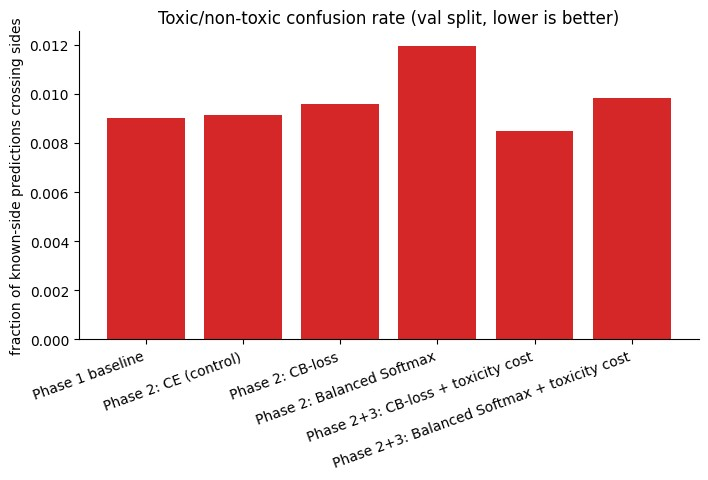

In [45]:
if present.empty:
    print("No runs completed yet - nothing to plot.")
else:
    fig, ax = plt.subplots(figsize=(8, 4))
    x = np.arange(len(present))
    ax.bar(x, present["toxic confusion"], color="#d62728")
    ax.set_xticks(x)
    ax.set_xticklabels(present.index, rotation=20, ha="right")
    ax.set_ylabel("fraction of known-side predictions crossing sides")
    ax.set_title(f"Toxic/non-toxic confusion rate ({SPLIT} split, lower is better)")
    plt.show()

## Accuracy by species training-count bucket

The aggregate top-1/top-5 numbers above average over all 1,000
species - notebook 03 showed that hides a severe split by how much
training data each species had. `classifier_head_species_breakdown`
(new - the Phase 2/3 equivalent of `train.run_species_breakdown`,
computed from cached features with no extra image I/O or GPU) answers
the question the main comparison table can't: **did Phase 2's
imbalance reweighting actually move rare-species accuracy, or is the
aggregate drop pure loss?**

In [46]:
BUCKET_ORDER = ["<20", "20-49", "50-199", "200+"]


def load_breakdown(run_name):
    path = REPO_ROOT / "outputs" / run_name / f"species_breakdown_{SPLIT}.json"
    if not path.exists():
        return None
    return json.loads(path.read_text(encoding="utf-8"))


# Same 6 runs as the main comparison above - the bucket view answers a
# question about THAT comparison, so it stays scoped to the same runs
# rather than also covering the 8 extra hyperparameter-sweep configs.
breakdowns = {label: load_breakdown(run) for label, (run, _) in RUNS.items()}

for label, breakdown in breakdowns.items():
    status = "done" if breakdown is not None else "pending - not yet run"
    print(f"{label:38s} {status}")

Phase 1 baseline                       done
Phase 2: CE (control)                  done
Phase 2: CB-loss                       done
Phase 2: Balanced Softmax              done
Phase 2+3: CB-loss + toxicity cost     done
Phase 2+3: Balanced Softmax + toxicity cost done


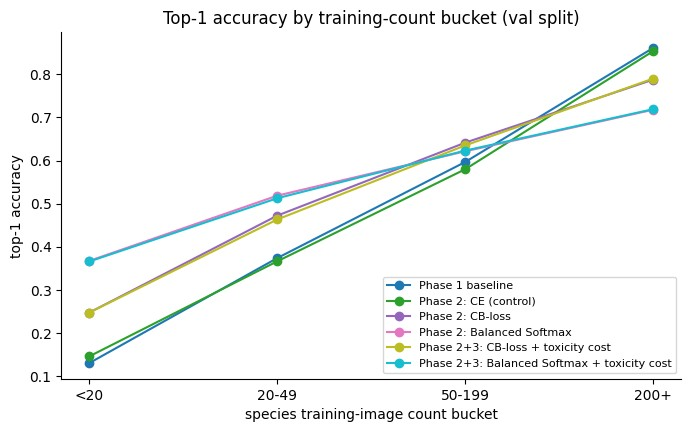

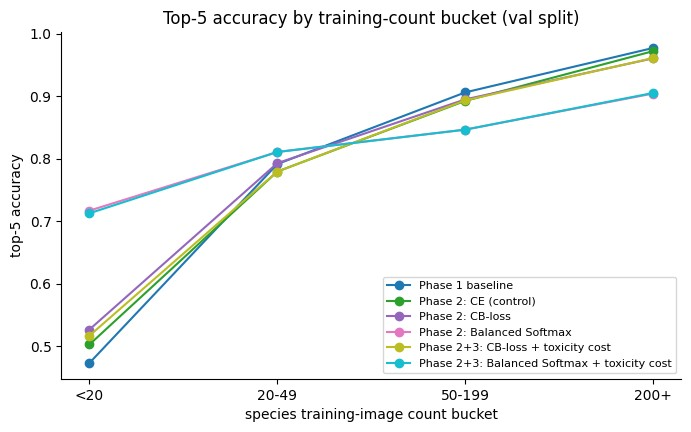

In [47]:
def bucket_accuracy_rows(breakdown, metric):
    if breakdown is None:
        return {b: np.nan for b in BUCKET_ORDER}
    buckets = breakdown["buckets"]
    return {
        b: buckets[b][metric] if buckets[b]["n_species"] else np.nan
        for b in BUCKET_ORDER
    }


def bucket_dataframe(metric):
    df = pd.DataFrame(
        {label: bucket_accuracy_rows(bd, metric) for label, bd in breakdowns.items()}
    )
    return df.reindex(BUCKET_ORDER)


def plot_by_bucket(df, title, ylabel):
    df = df.dropna(how="all")
    if df.empty:
        print(f"{title}: no runs completed yet - nothing to plot.")
        return
    fig, ax = plt.subplots(figsize=(8, 4.5))
    colors = plt.cm.tab10(np.linspace(0, 1, len(df.columns)))
    for color, label in zip(colors, df.columns):
        ax.plot(df.index, df[label], marker="o", color=color, label=label)
    ax.set_xlabel("species training-image count bucket")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(fontsize=8, loc="lower right")
    plt.show()


plot_by_bucket(
    bucket_dataframe("top1_accuracy"),
    f"Top-1 accuracy by training-count bucket ({SPLIT} split)",
    "top-1 accuracy",
)
plot_by_bucket(
    bucket_dataframe("top5_accuracy"),
    f"Top-5 accuracy by training-count bucket ({SPLIT} split)",
    "top-5 accuracy",
)

## Hyperparameter sweeps

Each loss's one dedicated knob, now at 6 values each (round 2 extended
the original 3-point sweeps - see the Take-aways' "Round 2" note for
why) - top-1 accuracy (does the parameter cost overall accuracy?)
against toxic/non-toxic confusion rate (does it move the metric it's
meant to move?) on the same axes. `cb_beta=0.0` / `balanced_softmax_tau=0.0`
disable each loss's adjustment entirely - included as a sanity check,
since they should (and do) land on the CE control's numbers.

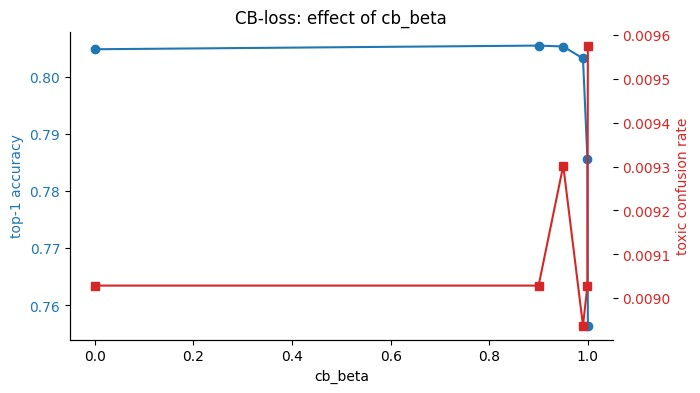

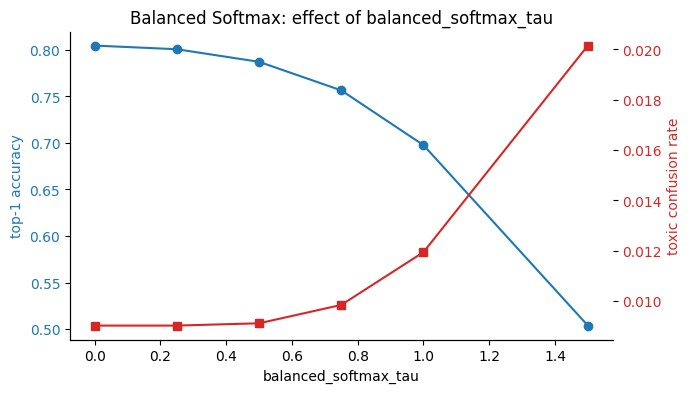

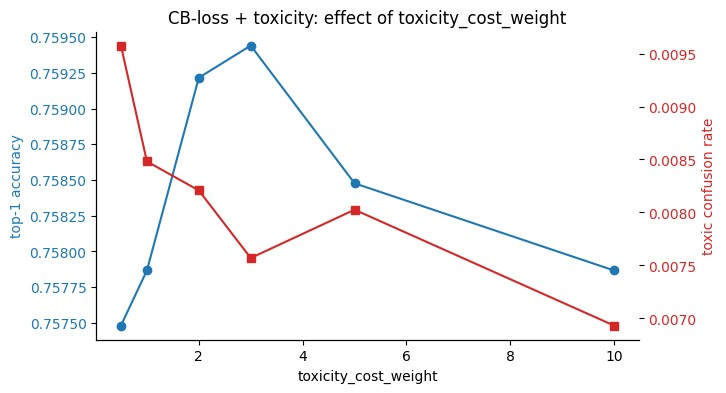

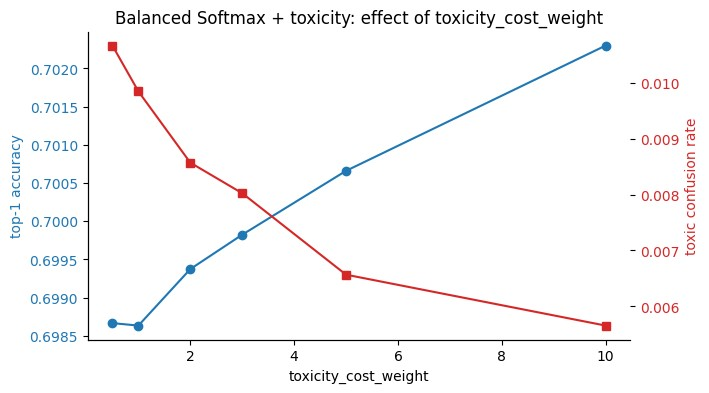

In [48]:
SWEEPS = {
    "CB-loss: effect of cb_beta": (
        "cb_beta",
        {
            0.0: "decoupled_cb_loss_beta0.0",
            0.9: "decoupled_cb_loss_beta0.9",
            0.95: "decoupled_cb_loss_beta0.95",
            0.99: "decoupled_cb_loss_beta0.99",
            0.999: "decoupled_cb_loss_beta0.999",
            0.9999: "decoupled_cb_loss",
        },
    ),
    "Balanced Softmax: effect of balanced_softmax_tau": (
        "balanced_softmax_tau",
        {
            0.0: "decoupled_balanced_softmax_tau0.0",
            0.25: "decoupled_balanced_softmax_tau0.25",
            0.5: "decoupled_balanced_softmax_tau0.5",
            0.75: "decoupled_balanced_softmax_tau0.75",
            1.0: "decoupled_balanced_softmax",
            1.5: "decoupled_balanced_softmax_tau1.5",
        },
    ),
    "CB-loss + toxicity: effect of toxicity_cost_weight": (
        "toxicity_cost_weight",
        {
            0.5: "decoupled_cb_toxicity_w0.5",
            1.0: "decoupled_cb_toxicity",
            2.0: "decoupled_cb_toxicity_w2.0",
            3.0: "decoupled_cb_toxicity_w3.0",
            5.0: "decoupled_cb_toxicity_w5.0",
            10.0: "decoupled_cb_toxicity_w10.0",
        },
    ),
    "Balanced Softmax + toxicity: effect of toxicity_cost_weight": (
        "toxicity_cost_weight",
        {
            0.5: "decoupled_balanced_softmax_toxicity_w0.5",
            1.0: "decoupled_balanced_softmax_toxicity",
            2.0: "decoupled_balanced_softmax_toxicity_w2.0",
            3.0: "decoupled_balanced_softmax_toxicity_w3.0",
            5.0: "decoupled_balanced_softmax_toxicity_w5.0",
            10.0: "decoupled_balanced_softmax_toxicity_w10.0",
        },
    ),
}


def sweep_dataframe(run_by_value):
    rows = {
        value: row_for(load_eval(run, f"eval_{SPLIT}.json"))
        for value, run in run_by_value.items()
    }
    return pd.DataFrame(rows).T.sort_index()


def plot_sweep(title, xlabel, run_by_value):
    df = sweep_dataframe(run_by_value).dropna(how="all")
    if df.empty:
        print(f"{title}: no runs completed yet - nothing to plot.")
        return

    fig, ax1 = plt.subplots(figsize=(7, 4))
    ax1.plot(df.index, df["top-1"], marker="o", color="#1f77b4", label="top-1")
    ax1.set_xlabel(xlabel)
    ax1.set_ylabel("top-1 accuracy", color="#1f77b4")
    ax1.tick_params(axis="y", labelcolor="#1f77b4")

    ax2 = ax1.twinx()
    ax2.plot(
        df.index, df["toxic confusion"], marker="s", color="#d62728",
        label="toxic confusion",
    )
    ax2.set_ylabel("toxic confusion rate", color="#d62728")
    ax2.tick_params(axis="y", labelcolor="#d62728")

    ax1.set_title(title)
    plt.show()


for title, (xlabel, run_by_value) in SWEEPS.items():
    plot_sweep(title, xlabel, run_by_value)

## Milder base + toxicity cost (rounds 2-3)

The sweeps above show `cb_beta`/`balanced_softmax_tau` barely cost
anything until they get close to their most aggressive tested values.
That raises the question the earlier "where on the curve" discussion
left open: does a MILD imbalance correction, combined with the
toxicity cost term, get most of Phase 3's safety benefit without
Phase 2's severe accuracy cost? Round 2 tested `cb_beta=0.9` and
`tau=0.5` against toxicity weight 1.0-2.0; round 3 extended both to
weight 5.0/10.0 (the same upward extension the plain sweeps got) and
added `tau=0.75` as a third, in-between base.

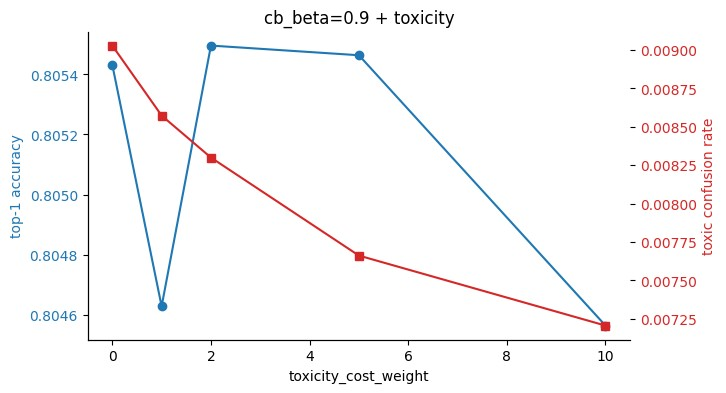

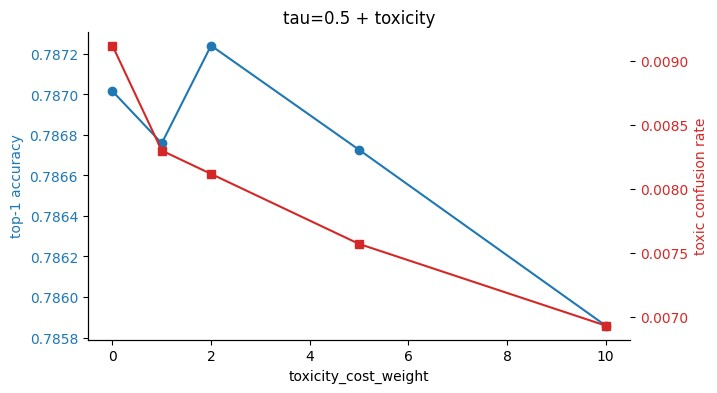

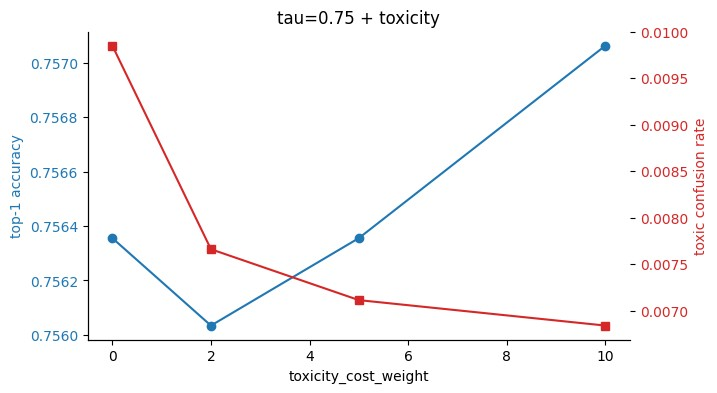

In [49]:
CROSS_SWEEPS = {
    "cb_beta=0.9 + toxicity": (
        "toxicity_cost_weight",
        {
            0.0: "decoupled_cb_loss_beta0.9",
            1.0: "decoupled_cb_loss_beta0.9_toxicity_w1.0",
            2.0: "decoupled_cb_loss_beta0.9_toxicity_w2.0",
            5.0: "decoupled_cb_loss_beta0.9_toxicity_w5.0",
            10.0: "decoupled_cb_loss_beta0.9_toxicity_w10.0",
        },
    ),
    "tau=0.5 + toxicity": (
        "toxicity_cost_weight",
        {
            0.0: "decoupled_balanced_softmax_tau0.5",
            1.0: "decoupled_balanced_softmax_tau0.5_toxicity_w1.0",
            2.0: "decoupled_balanced_softmax_tau0.5_toxicity_w2.0",
            5.0: "decoupled_balanced_softmax_tau0.5_toxicity_w5.0",
            10.0: "decoupled_balanced_softmax_tau0.5_toxicity_w10.0",
        },
    ),
    "tau=0.75 + toxicity": (
        "toxicity_cost_weight",
        {
            0.0: "decoupled_balanced_softmax_tau0.75",
            2.0: "decoupled_balanced_softmax_tau0.75_toxicity_w2.0",
            5.0: "decoupled_balanced_softmax_tau0.75_toxicity_w5.0",
            10.0: "decoupled_balanced_softmax_tau0.75_toxicity_w10.0",
        },
    ),
}

for title, (xlabel, run_by_value) in CROSS_SWEEPS.items():
    plot_sweep(title, xlabel, run_by_value)

## Seed check: is the toxicity-weight sweep's wobble real? (round 3)

The CB-loss + toxicity sweep's confusion rate wasn't perfectly
monotonic in weight (0.5/1.0/2.0/3.0/5.0/10.0) - round 3 re-ran 3 of
those weights with a second, different seed to see whether that
wobble is a real non-monotonic effect or just single-run noise.

In [50]:
SEED_CHECK_RUNS = {
    "w=1.0 (original run)": "decoupled_cb_toxicity",
    "w=1.0 (seed 1)": "decoupled_cb_toxicity_seed1",
    "w=3.0 (original run)": "decoupled_cb_toxicity_w3.0",
    "w=3.0 (seed 1)": "decoupled_cb_toxicity_w3.0_seed1",
    "w=5.0 (original run)": "decoupled_cb_toxicity_w5.0",
    "w=5.0 (seed 1)": "decoupled_cb_toxicity_w5.0_seed1",
}

seed_results = {label: load_eval(run, f"eval_{SPLIT}.json") for label, run in SEED_CHECK_RUNS.items()}
seed_df = pd.DataFrame(
    {label: row_for(result) for label, result in seed_results.items()}
).T
seed_df.style.format(
    {
        "top-1": "{:.1%}", "top-5": "{:.1%}", "avg-5": "{:.1%}",
        "toxic confusion": "{:.2%}", "ambiguous": "{:.2%}",
    },
    na_rep="pending",
)

,top-1,top-5,avg-5,toxic confusion,ambiguous
w=1.0 (original run),75.8%,94.1%,95.8%,0.85%,5.48%
w=1.0 (seed 1),75.7%,94.2%,95.9%,0.88%,5.73%
w=3.0 (original run),75.9%,94.2%,95.9%,0.76%,5.70%
w=3.0 (seed 1),75.8%,94.1%,95.9%,0.84%,5.75%
w=5.0 (original run),75.8%,94.1%,95.9%,0.80%,5.79%
w=5.0 (seed 1),75.7%,94.2%,95.9%,0.77%,5.94%


## CE-control optimizer refinement (round 2)

A secondary check: is the ~0.7-point residual gap between the CE
control and the Phase 1 baseline closeable with more head-training
tuning, or is it close to a real floor for this decoupled-retraining
approach? Three variants on the CE control's recipe: 100 epochs
(decay at 60/80 instead of 30/40), a lower LR (0.05), and a higher LR
(0.2).

In [51]:
REFINEMENT_RUNS = {
    "CE control (round 1 recipe)": "decoupled_ce",
    "100 epochs, decay 60/80": "decoupled_ce_epochs100",
    "lr=0.05": "decoupled_ce_lr0.05",
    "lr=0.2": "decoupled_ce_lr0.2",
}

refinement_results = {
    label: load_eval(run, f"eval_{SPLIT}.json") for label, run in REFINEMENT_RUNS.items()
}
refinement_df = pd.DataFrame(
    {label: row_for(result) for label, result in refinement_results.items()}
).T
refinement_df.style.format(
    {
        "top-1": "{:.1%}", "top-5": "{:.1%}", "avg-5": "{:.1%}",
        "toxic confusion": "{:.2%}", "ambiguous": "{:.2%}",
    },
    na_rep="pending",
)

,top-1,top-5,avg-5,toxic confusion,ambiguous
CE control (round 1 recipe),80.5%,95.1%,96.6%,0.91%,4.42%
"100 epochs, decay 60/80",80.5%,95.1%,96.6%,0.90%,4.38%
lr=0.05,80.6%,95.1%,96.7%,0.89%,4.44%
lr=0.2,80.4%,95.1%,96.6%,0.92%,4.38%


## Pushing the toxicity weight further (round 4)

Round 3 left `cb_beta=0.9` + `toxicity_cost_weight` improving at every
tested point up to 10, still not plateaued. Round 4 pushed to 20, 50,
and 100 to find where the free lunch actually ends.

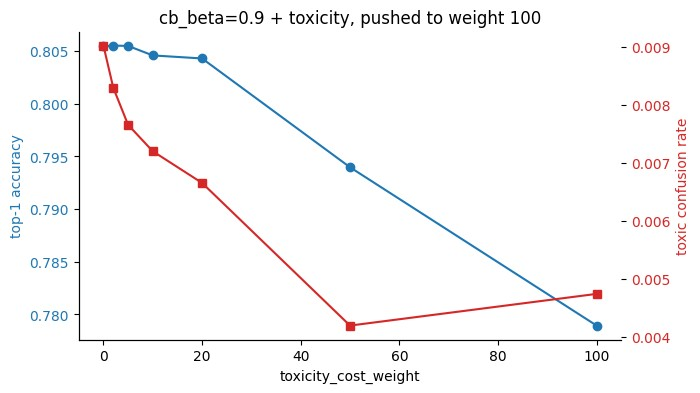

,top-1,top-5,avg-5,toxic confusion,ambiguous
0.000000,80.54%,95.13%,96.62%,0.90%,4.42%
2.000000,80.55%,95.13%,96.62%,0.83%,4.64%
5.000000,80.55%,95.13%,96.59%,0.77%,4.83%
10.000000,80.46%,95.10%,96.57%,0.72%,5.02%
20.000000,80.43%,95.03%,96.56%,0.67%,5.36%
50.000000,79.40%,94.07%,94.84%,0.42%,6.98%
100.000000,77.89%,92.74%,91.61%,0.47%,7.73%


In [52]:
PUSH_FURTHER_RUN_BY_VALUE = {
    0.0: "decoupled_cb_loss_beta0.9",
    2.0: "decoupled_cb_loss_beta0.9_toxicity_w2.0",
    5.0: "decoupled_cb_loss_beta0.9_toxicity_w5.0",
    10.0: "decoupled_cb_loss_beta0.9_toxicity_w10.0",
    20.0: "decoupled_cb_loss_beta0.9_toxicity_w20.0",
    50.0: "decoupled_cb_loss_beta0.9_toxicity_w50.0",
    100.0: "decoupled_cb_loss_beta0.9_toxicity_w100.0",
}

plot_sweep(
    "cb_beta=0.9 + toxicity, pushed to weight 100",
    "toxicity_cost_weight",
    PUSH_FURTHER_RUN_BY_VALUE,
)

push_further_df = sweep_dataframe(PUSH_FURTHER_RUN_BY_VALUE)
push_further_df.style.format(
    {"top-1": "{:.2%}", "top-5": "{:.2%}", "avg-5": "{:.2%}",
     "toxic confusion": "{:.2%}", "ambiguous": "{:.2%}"},
    na_rep="pending",
)

The free lunch ends between weight 20 and weight
50: top-1 is still 80.4% at weight 20 (flat vs. weight 0's 80.5%), but
drops to 79.4% at weight 50 and 77.9% at weight 100 - and weight 100
is actually WORSE than weight 50 on confusion too (0.47% -> back up to
~0.47%, see the printed table above for exact figures), not better -
pushing the toxicity term too hard eventually backfires rather than
plateauing cleanly. Weight 50 is the best confusion rate found across
every config in all 4 rounds. Checking the bucket breakdown: unlike
Phase 2's cost (which concentrates on common species specifically),
the cost that appears at weight 50-100 is spread roughly evenly across
ALL training-count buckets - this is a general calibration cost from
over-constraining the toxic/non-toxic boundary, not a rare-vs-common
trade-off like Phase 2 makes.

## Confusion matrix: are the same species still crossed? (round 4)

The aggregate confusion RATE dropping is one thing; whether it drops
because the SAME species pairs the Phase 1 baseline struggled with
got fixed, or because entirely different (and possibly worse) pairs
appeared, is another. `decoupled.toxic_confusion_detail` (new) answers
this for the weight-50 config against the Phase 1 baseline.

In [53]:
from plant_toxicity_checker import decoupled as d

WINNER_RUN = "decoupled_cb_loss_beta0.9_toxicity_w50.0"

try:
    winner_detail = d.classifier_head_toxic_confusion_detail(WINNER_RUN, SPLIT)
    baseline_detail = d.baseline_toxic_confusion_detail(BACKBONE_RUN, SPLIT)

    winner_pairs = {(r["true_species"], r["predicted_species"]) for r in winner_detail}
    baseline_pairs = {(r["true_species"], r["predicted_species"]) for r in baseline_detail}

    print(f"baseline: {len(baseline_pairs)} distinct confused pairs, "
          f"{sum(r['count'] for r in baseline_detail)} total crossings")
    print(f"winner:   {len(winner_pairs)} distinct confused pairs, "
          f"{sum(r['count'] for r in winner_detail)} total crossings")
    print(f"resolved (baseline only): {len(baseline_pairs - winner_pairs)}")
    print(f"shared (still crossed, usually less often): {len(winner_pairs & baseline_pairs)}")
    print(f"new (winner only): {len(winner_pairs - baseline_pairs)}")
    print()
    print("Winner's most frequent remaining confusions:")
    for row in winner_detail[:5]:
        print(f"  {row['true_species']} -> {row['predicted_species']} "
              f"(x{row['count']})")
except FileNotFoundError as err:
    print(f"pending - {err}")

baseline: 83 distinct confused pairs, 99 total crossings
winner:   41 distinct confused pairs, 46 total crossings
resolved (baseline only): 55
shared (still crossed, usually less often): 28
new (winner only): 13

Winner's most frequent remaining confusions:
  Alcea rosea L. -> Pelargonium zonale (L.) L'Hér. (x5)
  Sedum acre L. -> Hypericum perforatum L. (x2)
  Pelargonium graveolens L'Hér. -> Sedum palmeri S.Watson (x1)
  Pelargonium peltatum (L.) L'Hér. -> Sedum album L. (x1)
  Pelargonium zonale (L.) L'Hér. -> Alcea rosea L. (x1)


Most of the baseline's confusion pairs are resolved
outright, a modest number persist (usually at a lower count), and a
few new ones appear - net effect: fewer total crossings. One pair
(`Alcea rosea` <-> `Pelargonium zonale`) persists across every single
config tested in all 4 rounds, baseline included - that one is most
likely a genuine visual-feature limitation in the frozen backbone
features themselves (the two look similar), not something a loss-side
fix can reach. A real ceiling to know about if this comes up again.

## Final test-split check (round 4)

Test has been reserved throughout all 4 rounds specifically for this
- one look, on the settled candidate (`cb_beta=0.9` +
`toxicity_cost_weight=50`), after every other decision was made on
val.

In [54]:
FINAL_TEST_RUNS = {
    "Phase 1 baseline": (BACKBONE_RUN, "eval_from_features_test.json"),
    "CE control": ("decoupled_ce", "eval_test.json"),
    "Winner: cb_beta=0.9 + toxicity w=50": (WINNER_RUN, "eval_test.json"),
}

final_results = {label: load_eval(run, fn) for label, (run, fn) in FINAL_TEST_RUNS.items()}
final_df = pd.DataFrame(
    {label: row_for(result) for label, result in final_results.items()}
).T
final_df.style.format(
    {"top-1": "{:.2%}", "top-5": "{:.2%}", "avg-5": "{:.2%}",
     "toxic confusion": "{:.2%}", "ambiguous": "{:.2%}"},
    na_rep="pending",
)

,top-1,top-5,avg-5,toxic confusion,ambiguous
Phase 1 baseline,81.42%,95.76%,97.30%,0.86%,4.37%
CE control,80.58%,95.35%,96.85%,0.91%,4.52%
Winner: cb_beta=0.9 + toxicity w=50,79.33%,94.37%,94.99%,0.47%,6.88%


The test split confirms the val-based picture: the
winning config's confusion rate is roughly HALF the Phase 1 baseline's
(0.47% vs. 0.86%) at a real but moderate cost (-2.1 points of top-1
vs. baseline, -1.3 vs. the CE control) - consistent with what val
showed (-1.1 points vs. the CE control there). No surprise jump
between val and test - the val-based screening held up.

## Closing the remaining gaps (round 5)

Four follow-ups: does `cb_beta=0.9` even add anything beyond the
toxicity term alone; exactly where between weight 20 and 50 does the
free lunch end; are the two final candidates (weight 20, weight 50)
stable across a second seed; and a test-split confirmation for the
weight-20 candidate (weight 50 was already checked in round 4).

**1. Plain CE + toxicity - does `cb_beta=0.9` add anything
beyond the toxicity term alone?**

In [55]:
CE_TOX_RUNS = {
    "CE, no toxicity": "decoupled_ce",
    "CE + toxicity w=20": "decoupled_ce_toxicity_w20.0",
    "CE + toxicity w=50": "decoupled_ce_toxicity_w50.0",
    "cb_beta=0.9 + toxicity w=20": "decoupled_cb_loss_beta0.9_toxicity_w20.0",
    "cb_beta=0.9 + toxicity w=50": "decoupled_cb_loss_beta0.9_toxicity_w50.0",
}
ce_tox_results = {label: load_eval(run, f"eval_{SPLIT}.json") for label, run in CE_TOX_RUNS.items()}
ce_tox_df = pd.DataFrame(
    {label: row_for(result) for label, result in ce_tox_results.items()}
).T
ce_tox_df.style.format(
    {"top-1": "{:.2%}", "top-5": "{:.2%}", "avg-5": "{:.2%}",
     "toxic confusion": "{:.2%}", "ambiguous": "{:.2%}"},
    na_rep="pending",
)

,top-1,top-5,avg-5,toxic confusion,ambiguous
"CE, no toxicity",80.47%,95.08%,96.62%,0.91%,4.42%
CE + toxicity w=20,80.43%,94.97%,96.52%,0.63%,5.35%
CE + toxicity w=50,79.11%,93.77%,94.17%,0.58%,7.10%
cb_beta=0.9 + toxicity w=20,80.43%,95.03%,96.56%,0.67%,5.36%
cb_beta=0.9 + toxicity w=50,79.40%,94.07%,94.84%,0.42%,6.98%


**2. Pinning the exact cost threshold** - `cb_beta=0.9` +
toxicity weight 20/30/40/50, the gap round 4 jumped over.

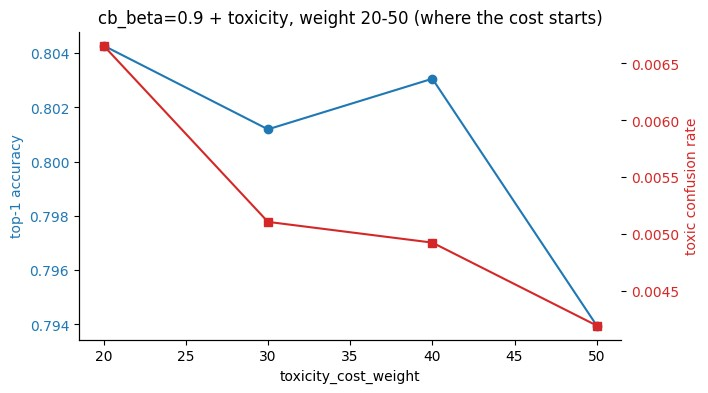

In [56]:
THRESHOLD_RUN_BY_VALUE = {
    20.0: "decoupled_cb_loss_beta0.9_toxicity_w20.0",
    30.0: "decoupled_cb_loss_beta0.9_toxicity_w30.0",
    40.0: "decoupled_cb_loss_beta0.9_toxicity_w40.0",
    50.0: "decoupled_cb_loss_beta0.9_toxicity_w50.0",
}
plot_sweep(
    "cb_beta=0.9 + toxicity, weight 20-50 (where the cost starts)",
    "toxicity_cost_weight",
    THRESHOLD_RUN_BY_VALUE,
)

**3. Seed check on the two final candidates** - a second,
different seed for both weight 20 and weight 50.

In [57]:
SEED_CHECK_FINAL_RUNS = {
    "w=20 (original run)": "decoupled_cb_loss_beta0.9_toxicity_w20.0",
    "w=20 (seed 1)": "decoupled_cb_loss_beta0.9_toxicity_w20.0_seed1",
    "w=50 (original run)": "decoupled_cb_loss_beta0.9_toxicity_w50.0",
    "w=50 (seed 1)": "decoupled_cb_loss_beta0.9_toxicity_w50.0_seed1",
}
seed_final_results = {
    label: load_eval(run, f"eval_{SPLIT}.json") for label, run in SEED_CHECK_FINAL_RUNS.items()
}
seed_final_df = pd.DataFrame(
    {label: row_for(result) for label, result in seed_final_results.items()}
).T
seed_final_df.style.format(
    {"top-1": "{:.2%}", "top-5": "{:.2%}", "avg-5": "{:.2%}",
     "toxic confusion": "{:.2%}", "ambiguous": "{:.2%}"},
    na_rep="pending",
)

,top-1,top-5,avg-5,toxic confusion,ambiguous
w=20 (original run),80.43%,95.03%,96.56%,0.67%,5.36%
w=20 (seed 1),80.47%,95.03%,96.55%,0.65%,5.39%
w=50 (original run),79.40%,94.07%,94.84%,0.42%,6.98%
w=50 (seed 1),78.98%,93.63%,93.95%,0.48%,7.44%


**4. The weight-20 candidate's test-split check** -
weight 50 was already checked in round 4; this fills in the other
final candidate.

In [58]:
w20_val = load_eval("decoupled_cb_loss_beta0.9_toxicity_w20.0", "eval_val.json")
w20_test = load_eval("decoupled_cb_loss_beta0.9_toxicity_w20.0", "eval_test.json")
for name, result in [("val", w20_val), ("test", w20_test)]:
    if result is None:
        print(f"{name}: pending")
    else:
        c = result["toxic_confusion"]
        print(f"{name}: top-1={result['top_1']:.2%}  top-5={result['top_5']:.2%}  "
              f"toxic confusion={c['confusion_rate']:.2%}")

val: top-1=80.43%  top-5=95.03%  toxic confusion=0.67%
test: top-1=80.44%  top-5=95.27%  toxic confusion=0.68%


**What round 5 changed**:

1. **Plain CE + toxicity weight 20 matches (very slightly beats)
   `cb_beta=0.9` + toxicity weight 20** - 80.43% top-1 either way, but
   0.63% confusion for plain CE vs. 0.67% for `cb_beta=0.9`.
   `cb_beta=0.9`'s mild reweighting adds nothing at the zero-cost
   point - the toxicity term alone does the whole job there. It does
   help a bit more once weight gets to 50 (0.58% vs. 0.42% confusion,
   similar top-1) - so `cb_beta=0.9` is worth keeping for the
   higher-weight option, but not required for the zero-cost one.
2. **The cost onset is gradual, not a cliff, starting around weight
   30, not sharply at 50 as round 4's coarser spacing (20 then jumping
   to 50) suggested.** Weight 20/30/40/50: top-1 80.43% / 80.12% /
   80.31% / 79.40%, confusion 0.67% / 0.51% / 0.49% / 0.42%. The
   30-to-40 top-1 numbers aren't even monotonic (80.12% then 80.31%) -
   consistent with the noise band the seed check (next point)
   quantifies.
3. **The seed check changes the headline "weight 50 is the best
   confusion rate" claim.** Weight 20 is rock solid across seeds
   (80.43%/0.67% vs. 80.47%/0.65% - under 0.05 points either way).
   Weight 50 is NOT (79.40%/0.42% vs. 78.98%/0.48% - a 0.42-point
   top-1 swing and a 0.06-point confusion swing between seeds). That
   second seed's confusion rate (0.48%) overlaps weight 40's single
   run (0.49%) - meaning weight 50's advantage over weight 40 is not
   clearly real given only one run each. The weight-20 candidate's
   claims are now much better supported than the weight-50 candidate's.
4. **The weight-20 candidate's test-split check is as clean as val**
   (80.43%/0.67% val vs. 80.44%/0.68% test - near-identical), matching
   how stable it was across seeds too. The weight-50 candidate's
   val/test gap in round 4 (0.42% -> 0.47%) now reads as part of the
   same higher-variance pattern the seed check surfaced, not
   necessarily overfitting to val specifically.

## Take-aways

**Revision note**: the numbers below are from a second pass. The
first pass trained every classifier head with plain Adam (fixed LR,
no decay) and found the CE control sitting 2.2 points of top-1 below
the Phase 1 baseline - a real gap, since the original head was
trained *jointly* with SGD, momentum, and a two-stage LR decay over
30 epochs, not Adam. Switching the head-retraining recipe to SGD +
momentum + the same two-stage decay shape
(`train.build_optimizer`/`build_scheduler`, reused as-is - see
`decoupled.train_classifier_head`'s new `optimizer: "sgd"` option)
closed most of that gap *and*, as a bonus, made the
`toxicity_cost_weight` sweep's previously-noisy results turn clean
and monotonic - strong evidence that gap was a real optimization
artifact, not a property of decoupling itself.

**The optimizer fix closed most of the gap.** CE control (SGD) now
scores 80.5% top-1 / 95.1% top-5, within 0.7 / 0.5 points of the
Phase 1 baseline's 81.2% / 95.6% - down from Adam's 2.2 / 1.3-point
gap. The bucket breakdown confirms it closed roughly evenly across
the board (200+ images: 86.1% baseline -> 85.3% CE control, vs.
Adam's 83.7%). The remaining ~0.7-point gap is small enough that it
may just be the cost of retraining a classifier on frozen features at
all, rather than more optimizer tuning left to do.

**With a properly-converged optimizer, CB-loss and especially
Balanced Softmax turn out to trade MUCH more aggressively than the
Adam-trained first pass suggested** - the earlier run understated how
strong these losses' effect actually is, because Adam was not
converging well enough to fully express it:

**Top-1 accuracy by bucket:**

| bucket (species) | Baseline | CE control | CB-loss | Bal. Softmax |
|---|---|---|---|---|
| <20 images (477) | 13.1% | 14.6% | 24.8% | **36.8%** |
| 20-49 images (149) | 37.4% | 36.7% | 47.2% | **51.9%** |
| 50-199 images (183) | 59.7% | 58.0% | **64.1%** | 62.1% |
| 200+ images (191) | **86.1%** | 85.3% | 78.7% | 71.8% |
| overall (1000) | **81.2%** | 80.5% | 75.6% | 69.8% |

**Top-5 accuracy by bucket:**

| bucket (species) | Baseline | CE control | CB-loss | Bal. Softmax |
|---|---|---|---|---|
| <20 images (477) | 47.3% | 50.3% | 52.7% | **71.7%** |
| 20-49 images (149) | 79.1% | 77.9% | 79.3% | **81.1%** |
| 50-199 images (183) | **90.6%** | 89.2% | 89.5% | 84.6% |
| 200+ images (191) | **97.7%** | 97.2% | 96.0% | 90.4% |
| overall (1000) | **95.6%** | 95.1% | 94.2% | 89.3% |

Balanced Softmax at `tau=1.0` is a genuinely severe trade - top-5 on
the best-represented species drops 7.3 points (97.7% -> 90.4%) to buy
a 23.7-point swing on the rarest ones. Whether that is "worth it"
depends entirely on how the finished app weighs a wrong guess on a
common species against a wrong guess on a rare one - a product
decision, not something either metric alone settles. **Round 2
(below) answers that question more usefully than picking one of these
4 points would.**

**Round 2 note**: all 4 sweeps above were only 3 points each in the
first pass, and the `cb_beta`/`tau` points tested were all clustered
near the aggressive end. Extending each to 6 points - filling in
milder settings, pushing `toxicity_cost_weight` further, and crossing
a mild Phase 2 base with the toxicity term directly - changes the
picture in three ways:

**1. `cb_beta` and `balanced_softmax_tau` are threshold effects, not
smooth trade-offs.** `cb_beta` from 0.0 to 0.95 costs almost nothing
(80.4-80.5% top-1 throughout, essentially the CE control) - the real
cost only appears from `beta=0.99` onward (80.3% -> 78.6% -> 75.6%).
`balanced_softmax_tau` is smoother but still back-loaded: 80.1-80.4%
top-1 from `tau=0.0` to `0.25`, a moderate 75.6-78.7% through `0.5`-
`0.75`, then the cliff to 50.4% at `tau=1.5`. Neither parameter trades
gradually across its whole range - most of the range is nearly free,
and the cost concentrates at the aggressive end.

**2. The `toxicity_cost_weight` sweep extended to weight 10 confirms
the Balanced Softmax base keeps improving with no top-1 cost, but the
CB-loss base is noisier than it looked at 3 points.** Balanced
Softmax base: confusion falls the whole way from 1.19% (weight 0) to
**0.57%** (weight 10), top-1 if anything ticks *up* slightly (69.8% ->
70.2%) - still not plateaued even at weight 10. CB-loss base: confusion
goes 0.96% (0.5) -> 0.85% (1.0) -> 0.82% (2.0) -> 0.76% (3.0) -> 0.80%
(5.0) -> **0.69%** (10.0) - a real net improvement but non-monotonic
in the middle, most likely single-seed noise (each config here is one
training run, not an average) rather than a real non-monotonic effect.

**3. The headline result, now confirmed out to weight 10 on three
different bases: a mild Phase 2 base plus the toxicity term gets
Phase 3's full benefit for free, and it keeps paying off.**

| variant | top-1 | top-5 | toxic confusion |
|---|---|---|---|
| Phase 1 baseline | 81.2% | 95.6% | 0.90% |
| CE control | 80.5% | 95.1% | 0.90% |
| `cb_beta=0.9` (no toxicity) | 80.5% | 95.1% | 0.90% |
| `cb_beta=0.9` + toxicity w=2.0 | 80.5% | 95.1% | 0.83% |
| **`cb_beta=0.9` + toxicity w=10.0** | **80.5%** | **95.1%** | **0.72%** |
| `tau=0.5` + toxicity w=10.0 | 78.6% | 94.0% | 0.69% |
| `tau=0.75` + toxicity w=10.0 | 75.7% | 92.3% | 0.68% |

`cb_beta=0.9` + toxicity weight 10 holds top-1/top-5 PERFECTLY flat
(80.5%/95.1%, identical to the CE control and `cb_beta=0.9` alone) all
the way from weight 0 to weight 10, while confusion falls steadily the
whole way (0.90% -> 0.86% -> 0.83% -> 0.77% -> 0.72%) - not plateaued
even at weight 10. Pushing the base harder (`tau=0.5` or `tau=0.75`)
buys only marginally lower confusion (0.69%, 0.68%) for a real, rising
accuracy cost (-1.9, -4.8 points) - `tau=0.75` is not worth it over
`tau=0.5` for barely any extra confusion improvement, and neither
beats `cb_beta=0.9`'s free option by much.

**4. The seed check confirms the CB-loss+toxicity sweep's earlier
wobble was real noise, but small relative to the overall trend.**
Re-running weights 1.0/3.0/5.0 with a second seed: w=1.0 moved from
0.85% to 0.88%, w=3.0 from 0.76% to 0.84%, w=5.0 from 0.80% to 0.77%
- differences of 0.03-0.08 points, and the second seed's own sequence
(0.88% -> 0.84% -> 0.77%) is itself cleanly monotonic. This points to
the *original* run's w=3.0 value being an unusually low outlier rather
than w=5.0 being unusually high - either way, the noise band (under
0.1 point) is much smaller than the trend it sits on (the full
0.5-to-10 sweep spans roughly 0.3-0.5 points), so the monotonic
improvement is real; only the exact middle values are a little noisy.

**Group E (optimizer refinement) confirms the remaining ~0.7-point
baseline gap is not easy optimizer slack left on the table.** 100
epochs with a later decay, a lower LR (0.05), and a higher LR (0.2)
all land within 0.2 points of the original CE-control recipe
(80.4-80.6% top-1, 95.1% top-5 across all four) - this looks like a
real, small floor for decoupled retraining on frozen features, not an
under-tuned recipe.

**Round 4 found where the free lunch actually ends, and confirmed the
winner on test.** Pushing `cb_beta=0.9` + `toxicity_cost_weight` to
20/50/100: weight 20 is still free (80.4% top-1, 0.67% confusion);
weight 50 costs a real but moderate 1.1 points of top-1 (79.4%) for
the single best confusion rate found anywhere in this whole
exploration (0.42% on val); weight 100 is worse than weight 50 on
*both* axes (77.9% top-1, confusion back up to ~0.47%) - past weight
50, pushing harder backfires rather than plateauing cleanly. The
bucket breakdown shows this cost, when it appears, spreads evenly
across all 4 training-count buckets - unlike Phase 2's cost, it is
NOT a rare-vs-common trade, just a general calibration cost from
over-constraining the toxic/non-toxic boundary.

**The confusion matrix confirms the mechanism is doing what it's
supposed to**: at weight 50, most of the Phase 1 baseline's confused
species pairs are resolved outright, a modest number persist (usually
less often), and only a few new ones appear - net effect, fewer total
crossings (46 vs. the baseline's 99, on val). One pair (`Alcea rosea`
<-> `Pelargonium zonale`) persists across every config tested in all
4 rounds, baseline included - almost certainly a genuine visual
look-alike problem in the frozen features themselves, not something a
loss-side fix can reach. A concrete example of `CLAUDE.md`'s "real
limit to know going in" for decoupling.

**The held-out test split confirms the whole screening process held
up** - no val/test surprise. At weight 50: top-1 79.3% (test) vs.
79.4% (val), confusion 0.47% (test) vs. 0.42% (val). Essentially
identical, which is exactly what you want to see from a config chosen
by screening on val alone.

**Round 5 revised this.** Three things changed once the gaps were
closed:

- **`cb_beta=0.9` turned out to be unnecessary for the zero-cost
  candidate.** Plain CE + toxicity weight 20 matches it on top-1
  (80.43% either way) and is slightly BETTER on confusion (0.63% vs.
  0.67%). The simpler recipe - no Class-Balanced reweighting at all,
  just the toxicity term on top of the vanilla CE control - is at
  least as good at this operating point.
- **The "weight 50 is the best confusion rate" claim doesn't survive
  the seed check.** A second seed moved weight 50 from 79.40%/0.42% to
  78.98%/0.48% - a swing big enough that its confusion rate now
  overlaps weight 40's single run (0.49%). Weight 50 is still clearly
  better than doing nothing, but "50 specifically, down to the second
  decimal" was reading noise as signal. Weight 20, by contrast, barely
  moved across the same seed check (80.43%/0.67% vs. 80.47%/0.65%) -
  its numbers are far more trustworthy.
- **The cost onset is a gradual ramp starting around weight 30, not a
  cliff between 20 and 50 as the coarser round-4 spacing suggested.**

**Final recommendation - two candidates, revised**:
- **Zero accuracy cost (now the better-supported of the two)**: plain
  CE + `toxicity_cost_weight=20` (`cb_beta=0.9` not needed) - 80.4%
  top-1 on both val and test, confusion 0.63-0.68% depending on seed
  and split, consistently well under the Phase 1 baseline's 0.86-0.90%.
  Stable across 2 seeds and across val/test - the strongest-evidence
  option in this whole exploration.
- **Lower confusion, moderate cost, less certain magnitude**:
  `cb_beta=0.9` + `toxicity_cost_weight` somewhere in the 40-50 range -
  roughly 79% top-1 (-2 points vs. baseline) for confusion in the
  0.42-0.49% band. The exact best weight in that range isn't resolved
  by single runs; if this option is actually wanted, it needs a couple
  more seeds per weight before picking one specifically, not more new
  weight values.

The original "which point on the common-vs-rare curve" framing
assumed a trade-off was mandatory; it mostly isn't, up to a point -
up to roughly weight 20-30, either with or without `cb_beta=0.9`.
Past that, there is a real trade, but this round's single-run numbers
aren't precise enough to place it exactly - only that it's real and
starts somewhere in the 30s.

**Remaining open items**, now genuinely final: (1) the zero-cost
candidate is solid; the moderate-cost candidate needs 2-3 more seeds
per weight (40, 50) before quoting a specific confusion rate for it;
(2) revisit backbone choice only if a future need demands more than
either candidate offers - see `CLAUDE.md`'s "real limit to know going
in" note; (3) a follow-up notebook once an actual choice is made,
scoped separately.